# M3–M5: Does an explicit instruction reduce spurious-feature sensitivity?

**Builds on M2** (baseline reproduction of Yang et al., ACL 2026, Table 6, Llama-3.1-8B-Instruct on SIG_Wiki).

**Hypothesis (M3, written before running):** Appending an explicit instruction to ignore format, style,
reasoning order, source and metadata will increase Robustness Rate (RR), because instruction-tuned models
follow explicit task constraints. Predicted: +5 to +10 RR on Format and Style, +3 to +5 on Source,
0 to +3 on Logic, ~0 on Meta.

**One variable changed:** one sentence appended to the authors' instruction.

| Arm | Extra sentence |
|---|---|
| baseline | none (authors' prompt, = M2) |
| generic | "Base your answer only on the information contained in the document." |
| specific | names the spurious features and says to ignore them |

Everything else is frozen: same weights, 4-bit NF4, greedy decoding, MAX_NEW_TOKENS=64, batch 8,
same 1,500 pairs, authors' scoring code.

**Kaggle:** GPU T4 x2, Internet On, Secret `HF_TOKEN`. Full run (3 arms) is about 95–110 minutes.

In [1]:
# 1. Install and get the authors' code + data   (same as M2)
!pip -q install -U "transformers>=4.45" accelerate bitsandbytes regex pandas matplotlib
!git clone -q https://github.com/maybenotime/RAG-SpuriousFeatures.git || echo "repo already cloned"
!ls RAG-SpuriousFeatures/test_data

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.11.2 which is incompatible.
ydata-profiling 4.18.4 requires pandas!=1.4.0,<3.0,>1.5, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.20.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
cudf-cu13 26.6.0 requires 

In [2]:
# 2. Configuration  (same as M2 + ARMS_TO_RUN + new output folder)
MODEL_ID       = "meta-llama/Llama-3.1-8B-Instruct"
SELF_SUBSET    = "self_preference_llama3_8b"
LOAD_IN_4BIT   = True
DO_SAMPLE      = False    # greedy = deterministic, so only the prompt differs between arms
TEMPERATURE    = 0.1
TOP_P          = 0.9
SEED           = 0
MAX_NEW_TOKENS = 64
BATCH_SIZE     = 8        # lower to 4 if CUDA out-of-memory
DRY_RUN        = False    # True = no model, fake answers, ~2 min pipeline test

ARMS_TO_RUN    = ["baseline", "generic", "specific"]   # drop "generic" to save ~35 min

import os
OUT_DIR = "/kaggle/working/rag_m4" if os.path.exists("/kaggle/working") else "/content/rag_m4"

REPORTED_RR = {"style": 10.0, "source": 15.5, "logic": 20.0, "format": 24.0, "meta": 94.0}   # paper Table 6
M2_RR       = {"style": 56.5, "source": 49.0, "logic": 68.7, "format": 64.5, "meta": 90.0}   # our M2 run
ORDER       = ["style", "source", "logic", "format", "meta"]

In [3]:
# 3. Load SIG_Wiki   (same as M2)
import json, os, sys, random, math, time
import pandas as pd, numpy as np

REPO = "RAG-SpuriousFeatures"
sys.path.insert(0, REPO)
os.makedirs(OUT_DIR, exist_ok=True)

with open(f"{REPO}/test_data/SIG_benchmark.json") as f:
    SIG = json.load(f)

OTHER_SELF = {"self_preference_llama3_8b", "self_preference_mistral_7b"} - {SELF_SUBSET}
inv = pd.DataFrame([{"type": t, "perturbation": s, "pairs": len(v), "used": s not in OTHER_SELF}
                    for t, subs in SIG.items() for s, v in subs.items()])
print("Total pairs used:", inv[inv.used].pairs.sum())
inv

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Total pairs used: 1500


,type,perturbation,pairs,used
0,format,format_preference_html,100,True
1,format,format_preference_json,100,True
2,format,format_preference_markdown,100,True
3,format,format_preference_yaml,100,True
4,style,simple_preference_llm,100,True
5,style,complex_preference_llm,100,True
6,logic,logic_preference_reverse,100,True
7,logic,logic_preference_random,100,True
8,logic,logic_preference_llm,100,True
9,source,source_preference_llm,100,True


In [4]:
# 4. Prompts: authors' instruction UNCHANGED + one extra sentence per arm  <-- THE M4 VARIABLE
INSTRUCTION = ("You are given a question and you MUST respond by EXTRACTING the answer (max 5 tokens) "
               "from the provided document. If the document does not contain the answer, respond with NO-RES. ")

ARMS = {
    "baseline": "",
    "generic":  "Base your answer only on the information contained in the document. ",
    "specific": ("The document may be written in a different format (HTML, JSON, Markdown, YAML), "
                 "a different writing style or reasoning order, and may include source or timestamp "
                 "metadata. These surface features do not change the facts: extract the answer from "
                 "the factual content only. "),
}
CURRENT_ARM = "baseline"

def build_prompt(question, doc, tokenizer=None):
    user = f"{INSTRUCTION}{ARMS[CURRENT_ARM]}\nDocuments:\n{doc}\nQuestion: {question}"
    if tokenizer is None:
        return user
    return tokenizer.apply_chat_template([{"role": "user", "content": user}],
                                         tokenize=False, add_generation_prompt=True)

def original_and_perturbed_docs(ptype, item):
    original = item["html_text"] if ptype == "meta" else f'{item["title"]} {item["text"]}'
    perturbed = item["perturbed_doc"] if ptype in ("meta", "format") else f'{item["title"]} {item["perturbed_doc"]}'
    return original, perturbed

# Sanity check: the three prompts must differ ONLY in the extra sentence
for a in ARMS:
    CURRENT_ARM = a
    print(f"===== {a} =====\n{build_prompt('<QUESTION>', '<DOC>')}\n")
CURRENT_ARM = "baseline"

===== baseline =====
You are given a question and you MUST respond by EXTRACTING the answer (max 5 tokens) from the provided document. If the document does not contain the answer, respond with NO-RES. 
Documents:
<DOC>
Question: <QUESTION>

===== generic =====
You are given a question and you MUST respond by EXTRACTING the answer (max 5 tokens) from the provided document. If the document does not contain the answer, respond with NO-RES. Base your answer only on the information contained in the document. 
Documents:
<DOC>
Question: <QUESTION>

===== specific =====
You are given a question and you MUST respond by EXTRACTING the answer (max 5 tokens) from the provided document. If the document does not contain the answer, respond with NO-RES. The document may be written in a different format (HTML, JSON, Markdown, YAML), a different writing style or reasoning order, and may include source or timestamp metadata. These surface features do not change the facts: extract the answer from the fa

In [5]:
# 5. Load the model   (same as M2; skipped in DRY_RUN)
tokenizer = model = None
if not DRY_RUN:
    import torch
    from huggingface_hub import login
    try:
        from kaggle_secrets import UserSecretsClient
        login(token=UserSecretsClient().get_secret("HF_TOKEN"))
    except Exception:
        login()
    from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    tokenizer.padding_side = "left"
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    quant = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                               bnb_4bit_compute_dtype=torch.float16) if LOAD_IN_4BIT else None
    model = AutoModelForCausalLM.from_pretrained(MODEL_ID, device_map="auto",
                                                 quantization_config=quant, dtype=torch.float16)
    model.eval()
    print("Loaded", MODEL_ID, "| GPU:", torch.cuda.get_device_name(0))

config.json:   0%|          | 0.00/855 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/55.4k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/296 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/184 [00:00<?, ?B/s]

Loaded meta-llama/Llama-3.1-8B-Instruct | GPU: Tesla T4


In [6]:
# 6. Generate for every arm (resumable cache, one file PER ARM)
from tqdm.auto import tqdm

def generate(prompts, seed):
    if DRY_RUN:
        out = []
        for p in prompts:
            rng = random.Random(f"{seed}|{p}")
            out.append(rng.choice(["NO-RES", "unknown"]) if rng.random() < 0.2 else "__GOLD__")
        return out
    torch.manual_seed(seed)
    enc = tokenizer(prompts, return_tensors="pt", padding=True, add_special_tokens=False).to(model.device)
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=DO_SAMPLE,
                             temperature=TEMPERATURE if DO_SAMPLE else None,
                             top_p=TOP_P if DO_SAMPLE else None,
                             pad_token_id=tokenizer.pad_token_id)
    new_tokens = out[:, enc["input_ids"].shape[1]:]
    return [t.strip() for t in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]

def run_tag(seed):
    # IMPORTANT: the arm name is in the tag, so each arm gets its own cache file
    m = MODEL_ID.split("/")[-1]
    mode = f"sample{TEMPERATURE}" if DO_SAMPLE else "greedy"
    return f"{m}_{'4bit' if LOAD_IN_4BIT else 'fp16'}_{mode}_seed{seed}_{CURRENT_ARM}{'_DRY' if DRY_RUN else ''}"

def run_all(seed):
    path = f"{OUT_DIR}/generations_{run_tag(seed)}.jsonl"
    done = {}
    if os.path.exists(path):
        for line in open(path):
            r = json.loads(line); done[(r["perturbation"], r["idx"])] = r
    jobs = []
    for ptype, subs in SIG.items():
        for sub, items in subs.items():
            if sub in OTHER_SELF:
                continue
            for i, item in enumerate(items):
                if (sub, i) not in done:
                    o, p = original_and_perturbed_docs(ptype, item)
                    jobs.append((ptype, sub, i, item, build_prompt(item["question"], o, tokenizer),
                                 build_prompt(item["question"], p, tokenizer)))
    print(f"{run_tag(seed)}: {len(done)} cached, {len(jobs)} to run")
    jobs.sort(key=lambda j: len(j[4]) + len(j[5]))
    t0 = time.time()
    with open(path, "a") as f:
        for b in tqdm(range(0, len(jobs), BATCH_SIZE)):
            batch = jobs[b:b + BATCH_SIZE]
            outs = generate([j[4] for j in batch] + [j[5] for j in batch], seed)
            n = len(batch)
            for j, o_ans, p_ans in zip(batch, outs[:n], outs[n:]):
                ptype, sub, i, item = j[:4]
                if DRY_RUN:
                    o_ans = item["answers"][0] if o_ans == "__GOLD__" else o_ans
                    p_ans = item["answers"][0] if p_ans == "__GOLD__" else p_ans
                rec = {"type": ptype, "perturbation": sub, "idx": i, "question": item["question"],
                       "answers": item["answers"], "org_result": o_ans, "perturbed_result": p_ans,
                       "arm": CURRENT_ARM}
                done[(sub, i)] = rec
                f.write(json.dumps(rec) + "\n")
                f.flush()
    print(f"{CURRENT_ARM} done in {(time.time() - t0) / 60:.1f} min")
    return list(done.values())

runs = {}
for arm in ARMS_TO_RUN:
    CURRENT_ARM = arm
    runs[arm] = run_all(SEED)
CURRENT_ARM = "baseline"
print({a: len(r) for a, r in runs.items()})   # every arm must show 1500

Llama-3.1-8B-Instruct_4bit_greedy_seed0_baseline: 0 cached, 1500 to run


  0%|          | 0/188 [00:00<?, ?it/s]

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


baseline done in 25.2 min
Llama-3.1-8B-Instruct_4bit_greedy_seed0_generic: 0 cached, 1500 to run


  0%|          | 0/188 [00:00<?, ?it/s]

generic done in 26.3 min
Llama-3.1-8B-Instruct_4bit_greedy_seed0_specific: 0 cached, 1500 to run


  0%|          | 0/188 [00:00<?, ?it/s]

specific done in 26.8 min
{'baseline': 1500, 'generic': 1500, 'specific': 1500}


In [7]:
# 7. Score exactly like the paper   (same as M2)
from normalize_answers import normalize_answer

def is_correct(prediction, golds):
    p = normalize_answer(prediction)
    return any(normalize_answer(g) in p for g in golds)

def score(records):
    rows = []
    for r in records:
        y, y_hat = is_correct(r["org_result"], r["answers"]), is_correct(r["perturbed_result"], r["answers"])
        rows.append({**r, "org_correct": y, "pert_correct": y_hat, "C": int(y) - int(y_hat)})
    return pd.DataFrame(rows)

def summarise(df):
    per_sub = (df.groupby(["type", "perturbation"])
                 .agg(n=("C", "size"),
                      RR=("C", lambda c: 100 * (c == 0).mean()),
                      WR=("C", lambda c: 100 * (c == -1).mean()),
                      LR=("C", lambda c: 100 * (c == 1).mean()),
                      acc_original=("org_correct", lambda x: 100 * x.mean()),
                      acc_perturbed=("pert_correct", lambda x: 100 * x.mean()))
                 .round(1).reset_index())
    per_type = per_sub.groupby("type")[["RR", "WR", "LR"]].mean().round(1)
    return per_sub, per_type

scored    = {arm: score(recs) for arm, recs in runs.items()}
summaries = {arm: summarise(df) for arm, df in scored.items()}
ARMS_DONE = list(scored)

## M4 — Results

In [8]:
# 8. Main table: RR per category for every arm + predicted vs actual
rr = pd.DataFrame({arm: summaries[arm][1]["RR"] for arm in ARMS_DONE}).loc[ORDER]
rr.insert(0, "M2_RR", pd.Series(M2_RR))
for arm in ARMS_DONE:
    if arm != "baseline":
        rr[f"delta_{arm}"] = (rr[arm] - rr["baseline"]).round(1)
rr["predicted_delta_specific"] = pd.Series({"format": "+5..+10", "style": "+5..+10", "source": "+3..+5",
                                            "logic": "0..+3", "meta": "~0"})
overall = {arm: round(100 * (scored[arm].C == 0).mean(), 1) for arm in ARMS_DONE}
print("Overall RR over all 1,500 pairs:", overall)
print("Determinism check: baseline here vs M2 (should be equal or within ~1 point)")
rr.to_csv(f"{OUT_DIR}/m4_rr_by_category.csv")
display(rr)

# WR / LR and accuracy, for the full picture
wl = pd.concat({arm: summaries[arm][1][["WR", "LR"]] for arm in ARMS_DONE}, axis=1).loc[ORDER]
acc = pd.concat({arm: scored[arm].groupby("type")[["org_correct", "pert_correct"]].mean().mul(100).round(1)
                 for arm in ARMS_DONE}, axis=1).loc[ORDER]
wl.to_csv(f"{OUT_DIR}/m4_wr_lr_by_category.csv"); acc.to_csv(f"{OUT_DIR}/m4_accuracy_by_category.csv")
display(wl); display(acc)

Overall RR over all 1,500 pairs: {'baseline': np.float64(69.0), 'generic': np.float64(72.8), 'specific': np.float64(71.9)}
Determinism check: baseline here vs M2 (should be equal or within ~1 point)


,M2_RR,baseline,generic,specific,delta_generic,delta_specific,predicted_delta_specific
type,,,,,,,
style,56.5,56.5,57.0,58.5,0.5,2.0,+5..+10
source,49.0,49.0,53.5,56.5,4.5,7.5,+3..+5
logic,68.7,68.7,74.7,69.0,6.0,0.3,0..+3
format,64.5,64.5,70.8,69.8,6.3,5.3,+5..+10
meta,90.0,90.0,91.0,90.8,1.0,0.8,~0


baseline       generic       specific      
             WR    LR      WR    LR       WR    LR
type                                              
style      21.5  22.0    21.5  21.5     22.0  19.5
source     27.5  23.5    25.5  21.0     25.5  18.0
logic      13.3  18.0    10.3  15.0     13.3  17.7
format     13.2  22.2    11.2  18.0     12.0  18.2
meta        5.2   4.8     3.0   6.0      3.0   6.2

baseline                  generic                 specific  \
       org_correct pert_correct org_correct pert_correct org_correct   
type                                                                   
style         52.5         52.0        49.0         49.0        45.5   
source        51.0         55.0        48.5         53.0        44.5   
logic         58.0         53.3        56.0         51.3        50.3   
format        59.2         50.2        54.2         47.5        50.0   
meta          32.8         33.2        41.2         38.2        37.2   

                     
       pert_correct  
type                 
style          48.0  
source         52.0  
logic          46.0  
format         43.8  
meta           34.0

In [9]:
# 9. Per-perturbation RR (16 rows) — where does the instruction help or hurt?
pp = pd.concat({arm: summaries[arm][0].set_index(["type", "perturbation"])["RR"] for arm in ARMS_DONE}, axis=1)
for arm in ARMS_DONE:
    if arm != "baseline":
        pp[f"delta_{arm}"] = (pp[arm] - pp["baseline"]).round(1)
pp.to_csv(f"{OUT_DIR}/m4_rr_per_perturbation.csv")
pp

baseline  generic  specific  \
type   perturbation                                               
format format_preference_html           47.0     55.0      61.0   
       format_preference_json           65.0     80.0      68.0   
       format_preference_markdown       80.0     77.0      75.0   
       format_preference_yaml           66.0     71.0      75.0   
logic  logic_preference_llm             72.0     74.0      72.0   
       logic_preference_random          66.0     73.0      69.0   
       logic_preference_reverse         68.0     77.0      66.0   
meta   metadata_datasource_twitter      89.0     90.0      94.0   
       metadata_datasource_wiki         88.0     89.0      89.0   
       metadata_timestamp_post          89.0     91.0      90.0   
       metadata_timestamp_pre           94.0     94.0      90.0   
source self_preference_llama3_8b        48.0     52.0      58.0   
       source_preference_llm            50.0     55.0      55.0   
style  complex_preference_llm           60.0     59.0      62.0   
       simple_preference_llm            53.0     55.0      55.0   

                                    delta_generic  delta_specific  
type   perturbation                                                
format format_preference_html                 8.0            14.0  
       format_preference_json                15.0             3.0  
       format_preference_markdown            -3.0            -5.0  
       format_preference_yaml                 5.0             9.0  
logic  logic_preference_llm                   2.0             0.0  
       logic_preference_random                7.0             3.0  
       logic_preference_reverse               9.0            -2.0  
meta   metadata_datasource_twitter            1.0             5.0  
       metadata_datasource_wiki               1.0             1.0  
       metadata_timestamp_post                2.0             1.0  
       metadata_timestamp_pre                 0.0            -4.0  
source self_preference_llama3_8b              4.0            10.0  
       source_preference_llm                  5.0             5.0  
style  complex_preference_llm                -1.0             2.0  
       simple_preference_llm                  2.0             2.0

In [10]:
# 10. Significance: exact McNemar test on paired robust / not-robust outcomes
def mcnemar_exact(b, c):
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(k + 1)) / 2 ** n)

def paired(a, b):
    x = scored[a][["type", "perturbation", "idx", "C"]].rename(columns={"C": "Ca"})
    y = scored[b][["perturbation", "idx", "C"]].rename(columns={"C": "Cb"})
    m = x.merge(y, on=["perturbation", "idx"])
    m["ra"], m["rb"] = m.Ca == 0, m.Cb == 0
    return m

rows = []
pairs = [(a, b) for a, b in [("baseline", "generic"), ("baseline", "specific"), ("generic", "specific")]
         if a in scored and b in scored]
for a, b in pairs:
    m = paired(a, b)
    for name, g in [("ALL", m)] + [(t, m[m.type == t]) for t in ORDER]:
        became_robust     = int((~g.ra & g.rb).sum())
        became_non_robust = int((g.ra & ~g.rb).sum())
        rows.append({"comparison": f"{a} -> {b}", "category": name, "n": len(g),
                     "became_robust": became_robust, "became_non_robust": became_non_robust,
                     "net": became_robust - became_non_robust,
                     "p_value": round(mcnemar_exact(became_robust, became_non_robust), 4)})
sig = pd.DataFrame(rows)
sig["significant_p<0.05"] = sig.p_value < 0.05
sig.to_csv(f"{OUT_DIR}/m4_mcnemar.csv", index=False)
sig

,comparison,category,n,became_robust,became_non_robust,net,p_value,significant_p<0.05
0,baseline -> generic,ALL,1500,185,128,57,0.0015,True
1,baseline -> generic,style,200,21,20,1,1.0000,False
2,baseline -> generic,source,200,31,22,9,0.2717,False
3,baseline -> generic,logic,300,38,20,18,0.0247,True
4,baseline -> generic,format,400,64,39,25,0.0176,True
5,baseline -> generic,meta,400,31,27,4,0.6940,False
6,baseline -> specific,ALL,1500,215,171,44,0.0285,True
7,baseline -> specific,style,200,34,30,4,0.7080,False
8,baseline -> specific,source,200,37,22,15,0.0674,False
9,baseline -> specific,logic,300,41,40,1,1.0000,False


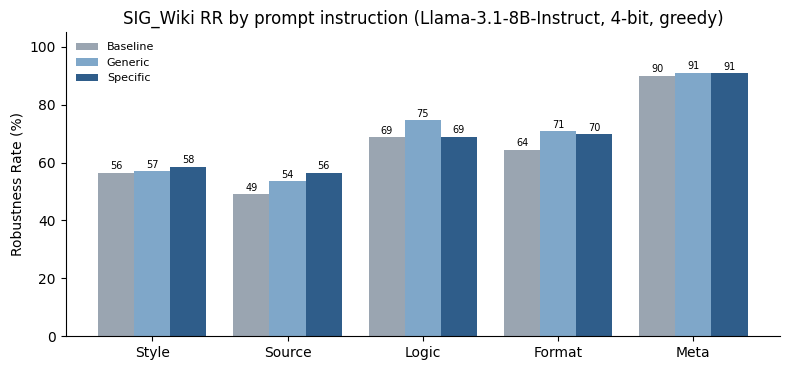

In [11]:
# 11. Figure: RR by category for each arm
import matplotlib.pyplot as plt
colors = {"baseline": "#9aa5b1", "generic": "#7fa7c9", "specific": "#2f5d8a"}
x = np.arange(len(ORDER)); k = len(ARMS_DONE); w = 0.8 / k
fig, ax = plt.subplots(figsize=(8, 3.8))
for j, arm in enumerate(ARMS_DONE):
    pos = x + (j - (k - 1) / 2) * w
    ax.bar(pos, rr[arm], w, label=arm.capitalize(), color=colors[arm])
    for xi, v in zip(pos, rr[arm]):
        ax.text(xi, v + 1.2, f"{v:.0f}", ha="center", fontsize=7)
ax.set_xticks(x, [o.capitalize() for o in ORDER]); ax.set_ylim(0, 105)
ax.set_ylabel("Robustness Rate (%)")
ax.set_title("SIG_Wiki RR by prompt instruction (Llama-3.1-8B-Instruct, 4-bit, greedy)")
ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/m4_rr_three_arms.png", dpi=200); plt.show()

## M5 — Failure analysis

In [12]:
# 12. Failure cases: pairs that STILL lose (C = 1) under the specific instruction, with evidence
TARGET = "specific" if "specific" in scored else ARMS_DONE[-1]

def snippet(doc, golds, w=160):
    d = doc.lower()
    for g in golds:
        i = d.find(g.lower())
        if i >= 0:
            return "..." + doc[max(0, i - w): i + len(g) + w].replace("\n", " ") + "..."
    return "(gold answer not found verbatim in this document)"

s = scored[TARGET].copy()
fails = s[s.C == 1].sample(frac=1, random_state=0).groupby("type").head(2).sort_values(["type", "perturbation"])
records = []
for _, r in fails.iterrows():
    item = SIG[r["type"]][r["perturbation"]][r["idx"]]
    o_doc, p_doc = original_and_perturbed_docs(r["type"], item)
    rec = {"type": r["type"], "perturbation": r["perturbation"], "idx": r["idx"], "question": r["question"],
           "gold": r["answers"][:3], "original_answer": r["org_result"], "perturbed_answer": r["perturbed_result"],
           "gold_in_perturbed_doc": snippet(p_doc, r["answers"])}
    records.append(rec)
    print(f"[{r['perturbation']} #{r['idx']}] Q: {r['question']}\n  gold: {r['answers'][:3]}\n"
          f"  original  -> {r['org_result']!r}\n  perturbed -> {r['perturbed_result']!r}\n"
          f"  evidence  : {rec['gold_in_perturbed_doc'][:400]}\n")
pd.DataFrame(records).to_csv(f"{OUT_DIR}/m5_failure_cases_{TARGET}.csv", index=False)

[format_preference_html #7] Q: when was the last time the crows were in the grand final
  gold: ['2017']
  original  -> '2017'
  perturbed -> 'NO-RES. The document does not contain information about the Crows.'
  evidence  : ... <html lang="en"> <head>     <meta charset="UTF-8">   <title>2017 AFL finals series</title> </head> <body>   <p>by 29 points to earn their third finals appearance in as many years. The two sides met in the finals once before,...

[format_preference_json #71] Q: where can i get a state issued id
  gold: ["each state 's DMV", 'DMV']
  original  -> 'DMV'
  perturbed -> 'ID cards can be issued without a birth certificate.'
  evidence  : ...in Act 23", "text": "that an applicant for an ID card must pay the $28 fee unless the applicant requests that the ID be issued for free. In September 2011, the DMV began posting signs instructing applicants seeking free \"ID cards used for voting\" to check the appropriate box on the application form. As initially impleme...

[log

In [13]:
# 13. How many failures did the instruction FIX vs CREATE? (baseline LR -> specific)
if "specific" in scored:
    m = paired("baseline", "specific")
    fixed   = m[(m.Ca == 1) & (m.Cb == 0)]
    created = m[(m.Ca == 0) & (m.Cb == 1)]
    print(f"Baseline losses fixed by specific instruction: {len(fixed)} | new losses created: {len(created)}")
    print(pd.DataFrame({"fixed": fixed.type.value_counts(), "created": created.type.value_counts()})
            .reindex(ORDER).fillna(0).astype(int))

Baseline losses fixed by specific instruction: 117 | new losses created: 87
        fixed  created
type                  
style      21       14
source     18        8
logic      20       20
format     44       28
meta       14       17


In [14]:
# 14. Floor effect: standard RR counts 'wrong on both' as robust.
#     Conditional RR = share of ORIGINALLY-CORRECT answers that stay correct after perturbation.
cond = pd.DataFrame({arm: scored[arm][scored[arm].org_correct].groupby("type")["pert_correct"].mean().mul(100).round(1)
                     for arm in ARMS_DONE}).loc[ORDER]
both_wrong = pd.DataFrame({arm: scored[arm].assign(bw=~scored[arm].org_correct & ~scored[arm].pert_correct)
                           .groupby("type")["bw"].mean().mul(100).round(1) for arm in ARMS_DONE}).loc[ORDER]
cmp_floor = pd.concat({"standard_RR": rr[ARMS_DONE], "conditional_RR": cond,
                       "%_pairs_wrong_on_both": both_wrong}, axis=1)
cmp_floor.to_csv(f"{OUT_DIR}/m5_floor_effect.csv")
cmp_floor

standard_RR                  conditional_RR                   \
          baseline generic specific       baseline generic specific   
type                                                                  
style         56.5    57.0     58.5           58.1    56.1     57.1   
source        49.0    53.5     56.5           53.9    56.7     59.6   
logic         68.7    74.7     69.0           69.0    73.2     64.9   
format        64.5    70.8     69.8           62.4    66.8     63.5   
meta          90.0    91.0     90.8           85.5    85.5     83.2   

       %_pairs_wrong_on_both                   
                    baseline generic specific  
type                                           
style                   26.0    29.5     32.5  
source                  21.5    26.0     30.0  
logic                   28.7    33.7     36.3  
format                  27.5    34.5     38.0  
meta                    62.0    55.8     59.8

In [15]:
# 15. Confound check: did the instruction change answer behaviour (refusals / long answers)?
rows = []
for arm in ARMS_DONE:
    df = scored[arm]
    allr = pd.concat([df.org_result, df.perturbed_result]).astype(str)
    rows.append({"arm": arm,
                 "NO-RES_%": round(100 * allr.str.contains("NO-RES").mean(), 1),
                 "answers_>5_words_%": round(100 * (allr.str.split().str.len() > 5).mean(), 1),
                 "median_words": allr.str.split().str.len().median(),
                 "acc_original_%": round(100 * df.org_correct.mean(), 1),
                 "acc_perturbed_%": round(100 * df.pert_correct.mean(), 1)})
behaviour = pd.DataFrame(rows).set_index("arm")
behaviour.to_csv(f"{OUT_DIR}/m5_answer_behaviour.csv")
behaviour

,NO-RES_%,answers_>5_words_%,median_words,acc_original_%,acc_perturbed_%
arm,,,,,
baseline,30.0,39.5,3.0,49.9,47.2
generic,34.4,51.7,7.0,49.7,46.7
specific,34.5,42.6,3.0,45.3,43.3


In [16]:
# 16. HTML deep-dive: in losing HTML pairs, is the gold answer even present verbatim in the HTML?
html = scored[TARGET][scored[TARGET].perturbation == "format_preference_html"]
def gold_in_doc(r):
    item = SIG[r["type"]][r["perturbation"]][r["idx"]]
    _, p_doc = original_and_perturbed_docs(r["type"], item)
    return any(g.lower() in p_doc.lower() for g in r["answers"])
html = html.assign(gold_present=html.apply(gold_in_doc, axis=1))
print(html.groupby("C")["gold_present"].agg(["size", "mean"]).rename(index={-1: "win", 0: "robust", 1: "lose"}))

        size      mean
C                     
win        4  1.000000
robust    61  1.000000
lose      35  0.971429


In [17]:
# 17. Pack every output for download (Output tab -> rag_m4.zip)
!cd /kaggle/working && zip -rq rag_m4.zip rag_m4 && ls -lh rag_m4 rag_m4.zip

-rw-r--r-- 1 root root 338K Nov 25 17:32 rag_m4.zip

rag_m4:
total 1.7M
-rw-r--r-- 1 root root 518K Nov 25 16:38 generations_Llama-3.1-8B-Instruct_4bit_greedy_seed0_baseline.jsonl
-rw-r--r-- 1 root root 554K Nov 25 17:05 generations_Llama-3.1-8B-Instruct_4bit_greedy_seed0_generic.jsonl
-rw-r--r-- 1 root root 518K Nov 25 17:32 generations_Llama-3.1-8B-Instruct_4bit_greedy_seed0_specific.jsonl
-rw-r--r-- 1 root root  321 Nov 25 17:32 m4_accuracy_by_category.csv
-rw-r--r-- 1 root root 1012 Nov 25 17:32 m4_mcnemar.csv
-rw-r--r-- 1 root root  294 Nov 25 17:32 m4_rr_by_category.csv
-rw-r--r-- 1 root root  877 Nov 25 17:32 m4_rr_per_perturbation.csv
-rw-r--r-- 1 root root  65K Nov 25 17:32 m4_rr_three_arms.png
-rw-r--r-- 1 root root  258 Nov 25 17:32 m4_wr_lr_by_category.csv
-rw-r--r-- 1 root root  174 Nov 25 17:32 m5_answer_behaviour.csv
-rw-r--r-- 1 root root 4.1K Nov 25 17:32 m5_failure_cases_specific.csv
-rw-r--r-- 1 root root  497 Nov 25 17:32 m5_floor_effect.csv
